# Skincare Market Analysis
**Question:** what does a higher price actually buy you in skincare?

Dataset: 482 products from 210 brands across 27 countries, covering price, size, segment, rating, marketing claims and (partial) INCI ingredient lists.

**Part 1** analyses price, ratings and claims. **Part 2** enriches the data with full ingredient lists from the Open Beauty Facts API.

## 1. Load and clean
Extract numeric price and size, compute **price per ml** (the fair way to compare products of different sizes), and flag fragrance and denatured alcohol in the ingredient lists.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'sans-serif'

# Load
df = pd.read_excel('Skincare_Products_Complete.xlsx', sheet_name='All Products')

# Clean price — extract number
df['Price_EUR'] = df['Price (approx)'].str.extract(r'(\d+\.?\d*)').astype(float)

# Clean size — extract number
df['Size_ml'] = df['Size'].str.extract(r'(\d+\.?\d*)').astype(float)

# Price per ml
df['Price_per_ml'] = (df['Price_EUR'] / df['Size_ml']).round(3)

# Fragrance flag — check INCI for parfum/fragrance
df['Contains_Fragrance'] = df['INCI (partial)'].str.lower()\
    .str.contains('parfum|fragrance', na=False)

# Alcohol flag
df['Contains_Alcohol'] = df['INCI (partial)'].str.lower()\
    .str.contains('alcohol denat|denatured alcohol', na=False)

# Rating as number
df['Avg Rating'] = pd.to_numeric(df['Avg Rating'], errors='coerce')

# Segment order for charts
segment_order = ['Budget','Mass','Mid-range','Pharmacy','Active',
                 'Natural','Organic','Premium','Clinical','Professional',
                 'Luxury']

print(f"Dataset loaded: {len(df)} products, {df['Brand'].nunique()} brands")
df.head(3)

## 2. Price per ml across segments
Only segments with at least 5 products are included, ordered by median price per ml. The y-axis is capped at €12/ml so the extreme outliers don't flatten the chart.

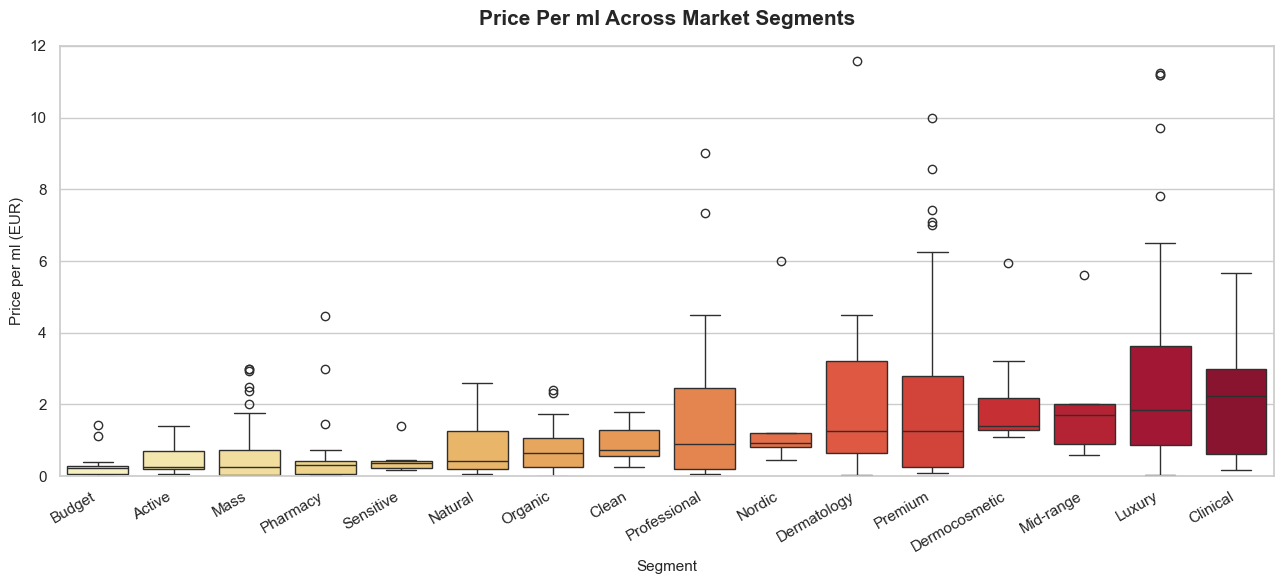


Median price per ml by segment:
Segment
Budget           0.217
Active           0.267
Mass             0.267
Pharmacy         0.300
Sensitive        0.357
Natural          0.435
Organic          0.650
Clean            0.733
Professional     0.887
Nordic           0.933
Dermatology      1.247
Premium          1.267
Dermocosmetic    1.400
Mid-range        1.700
Luxury           1.833
Clinical         2.234


In [2]:
# Filter to skincare products only, remove devices/fragrances
skincare = df[df['Category of Brand'] if 'Category of Brand' in df.columns 
              else df['Product Type'].notna()].copy()

# Filter segments we have enough data for
valid_segments = df['Segment'].value_counts()
valid_segments = valid_segments[valid_segments >= 5].index.tolist()
plot_df = df[df['Segment'].isin(valid_segments) & df['Price_per_ml'].notna()]

# Order by median price
order = plot_df.groupby('Segment')['Price_per_ml'].median()\
               .sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=plot_df, x='Segment', y='Price_per_ml',
            order=order, palette='YlOrRd', ax=ax)

ax.set_title('Price Per ml Across Market Segments', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Segment', fontsize=11)
ax.set_ylabel('Price per ml (EUR)', fontsize=11)
ax.set_ylim(0, 12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('chart1_price_per_segment.png', dpi=150)
plt.show()

# Print median prices
print("\nMedian price per ml by segment:")
print(plot_df.groupby('Segment')['Price_per_ml'].median()\
      .sort_values().round(3).to_string())

## 3. Do "fragrance-free" claims match the ingredients?
Cross-check the marketing claim against the INCI list: does any product claiming to be fragrance-free contain parfum or fragrance?

Fragrance Claims vs INCI Reality:
                               No Parfum in INCI  Parfum Found in INCI
Does NOT claim Fragrance-Free                302                    22
Claims Fragrance-Free                        158                     0

Products claiming fragrance-free: 158
Of those, contain parfum in INCI: 0 (0.0%)


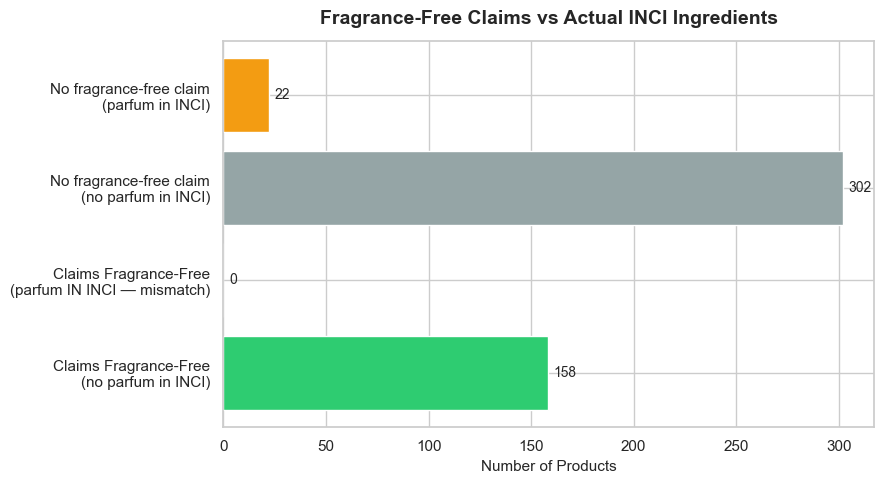

In [3]:
# Products claiming fragrance-free
claims_ff = df['Free-From / Claims'].str.lower()\
              .str.contains('fragrance-free|fragrance free', na=False)

df['Claims_FragranceFree'] = claims_ff

# Crosstab
ct = pd.crosstab(df['Claims_FragranceFree'], df['Contains_Fragrance'])
ct.index = ['Does NOT claim Fragrance-Free', 'Claims Fragrance-Free']
ct.columns = ['No Parfum in INCI', 'Parfum Found in INCI']

print("Fragrance Claims vs INCI Reality:")
print(ct)
print()

# Calculate the inconsistency
ff_products = df[df['Claims_FragranceFree'] == True]
has_fragrance = ff_products[ff_products['Contains_Fragrance'] == True]
pct = len(has_fragrance) / len(ff_products) * 100
print(f"Products claiming fragrance-free: {len(ff_products)}")
print(f"Of those, contain parfum in INCI: {len(has_fragrance)} ({pct:.1f}%)")

# Bar chart
fig, ax = plt.subplots(figsize=(9, 5))
categories = ['Claims Fragrance-Free\n(no parfum in INCI)',
              'Claims Fragrance-Free\n(parfum IN INCI — mismatch)',
              'No fragrance-free claim\n(no parfum in INCI)',
              'No fragrance-free claim\n(parfum in INCI)']

values = [
    len(ff_products[ff_products['Contains_Fragrance'] == False]),
    len(has_fragrance),
    len(df[(df['Claims_FragranceFree']==False) & (df['Contains_Fragrance']==False)]),
    len(df[(df['Claims_FragranceFree']==False) & (df['Contains_Fragrance']==True)])
]
colors = ['#2ecc71','#e74c3c','#95a5a6','#f39c12']

bars = ax.barh(categories, values, color=colors, edgecolor='white')
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_title('Fragrance-Free Claims vs Actual INCI Ingredients',
             fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Number of Products', fontsize=11)
plt.tight_layout()
plt.savefig('chart2_fragrance_claims.png', dpi=150)
plt.show()

## 4. Does a higher price mean better ratings?
Average rating by segment (error bars show standard deviation). The red line is the overall average.

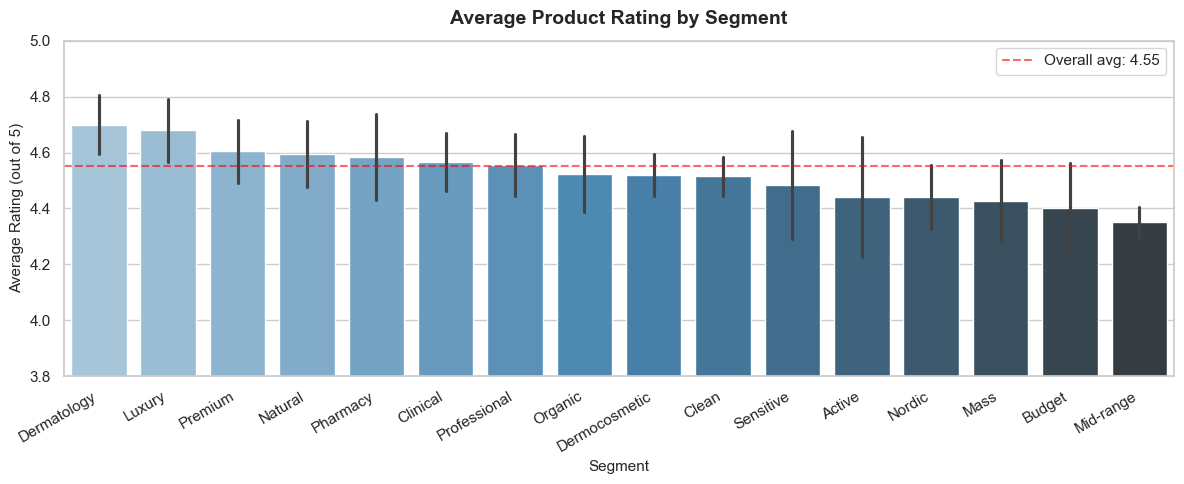


Mean rating by segment:
Segment
Dermatology      4.70
Luxury           4.68
Premium          4.60
Natural          4.60
Pharmacy         4.58
Clinical         4.56
Professional     4.56
Organic          4.52
Dermocosmetic    4.52
Clean            4.51
Sensitive        4.48
Active           4.44
Nordic           4.44
Mass             4.43
Budget           4.40
Mid-range        4.35


In [5]:
rating_df = df[df['Segment'].isin(valid_segments) & df['Avg Rating'].notna()]

order_rating = rating_df.groupby('Segment')['Avg Rating'].mean()\
                         .sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=rating_df, x='Segment', y='Avg Rating',
            order=order_rating, palette='Blues_d', ax=ax, ci='sd')

ax.set_title('Average Product Rating by Segment', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Segment', fontsize=11)
ax.set_ylabel('Average Rating (out of 5)', fontsize=11)
ax.set_ylim(3.8, 5.0)
ax.axhline(y=rating_df['Avg Rating'].mean(), color='red',
           linestyle='--', alpha=0.6, label=f"Overall avg: {rating_df['Avg Rating'].mean():.2f}")
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('chart3_ratings_by_segment.png', dpi=150)
plt.show()

print("\nMean rating by segment:")
print(rating_df.groupby('Segment')['Avg Rating'].mean()\
      .sort_values(ascending=False).round(2).to_string())

## 5. Best-value sunscreens
The 20 cheapest sunscreens with UV protection, ranked by price per ml.

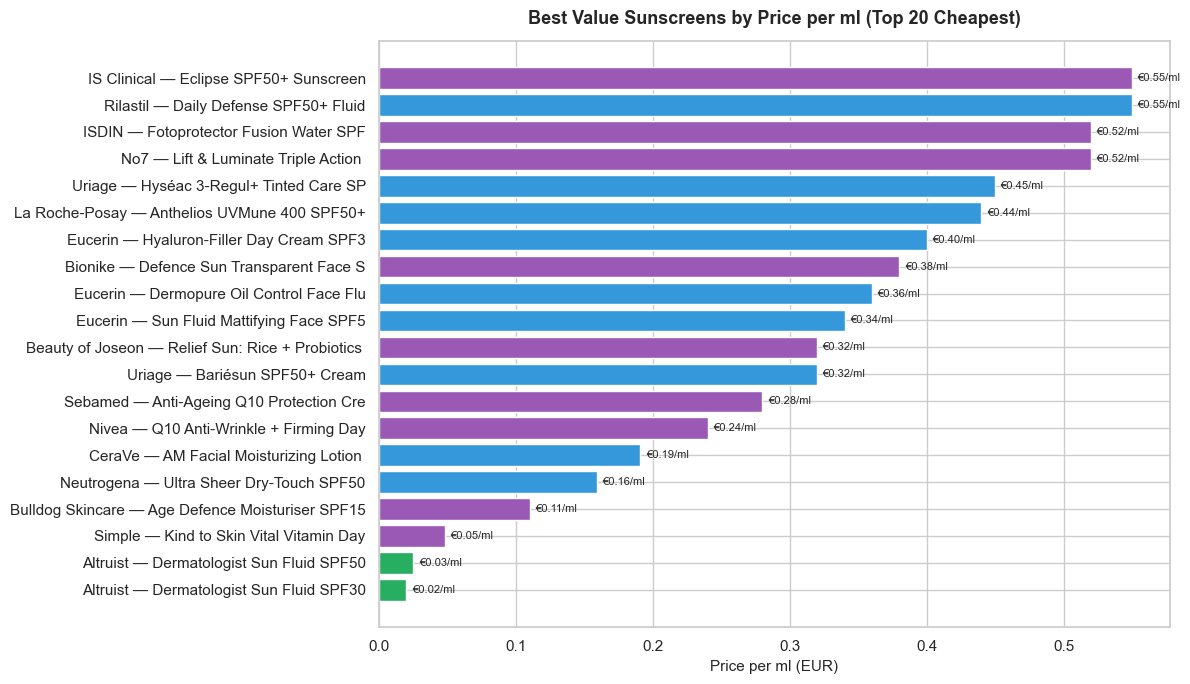

In [6]:
spf = df[df['Product Type'].str.contains('Sunscreen|SPF', na=False) &
         df['Skin Concern'].str.contains('UV', na=False) &
         df['Price_per_ml'].notna()].copy()

spf_sorted = spf.sort_values('Price_per_ml').head(20)

fig, ax = plt.subplots(figsize=(12, 7))
colors = ['#27ae60' if s == 'Budget' else '#3498db' if s == 'Pharmacy'
          else '#e67e22' if s == 'Active' else '#9b59b6'
          for s in spf_sorted['Segment']]

bars = ax.barh(spf_sorted['Brand'] + ' — ' + spf_sorted['Product Name'].str[:30],
               spf_sorted['Price_per_ml'], color=colors)
ax.bar_label(bars, fmt='€%.2f/ml', padding=4, fontsize=8)
ax.set_title('Best Value Sunscreens by Price per ml (Top 20 Cheapest)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Price per ml (EUR)', fontsize=11)
plt.tight_layout()
plt.savefig('chart4_sunscreen_value.png', dpi=150)
plt.show()

## 6. Nordic vs French brands
How do Nordic brands (Sweden, Finland, Denmark, Norway) compare with French brands on price, rating and product mix?

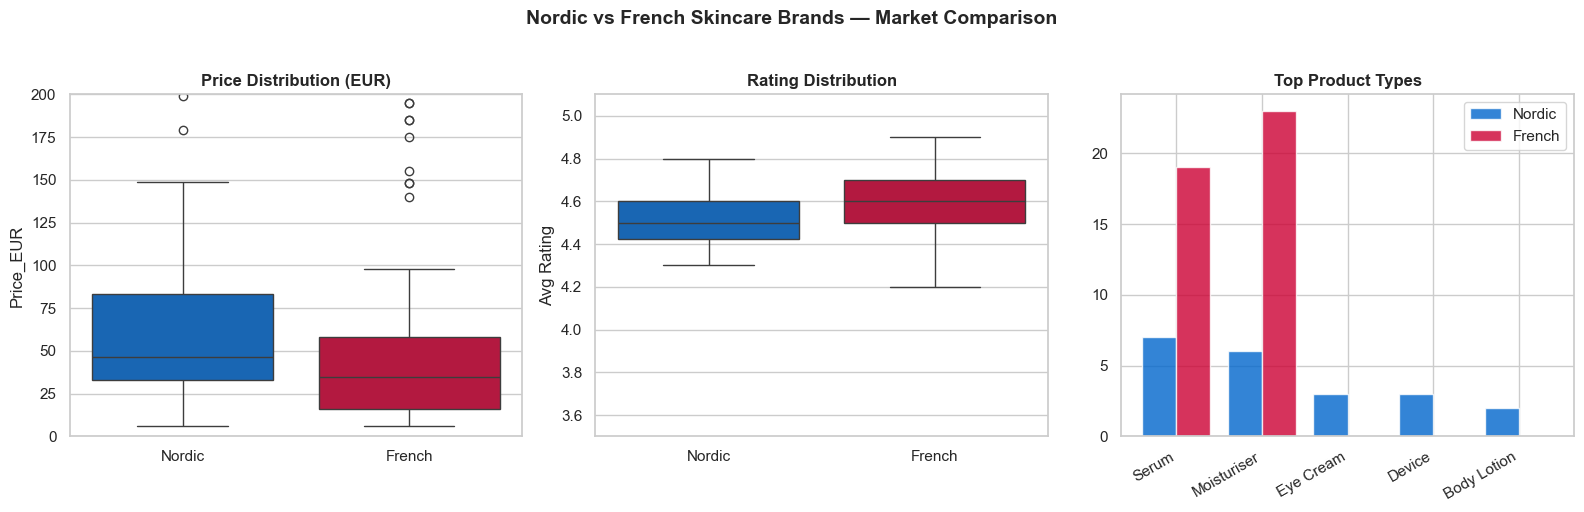

Nordic brands summary:
       Price_EUR  Avg Rating
count      38.00       38.00
mean       75.84        4.53
std        72.83        0.12
min         6.00        4.30
25%        33.00        4.43
50%        46.50        4.50
75%        83.25        4.60
max       299.00        4.80

French brands summary:
       Price_EUR  Avg Rating
count     107.00      107.00
mean       52.84        4.60
std        62.86        0.15
min         6.00        4.20
25%        16.00        4.50
50%        35.00        4.60
75%        58.00        4.70
max       395.00        4.90


In [7]:
nordic = df[df['Country of Brand'].str.contains('Sweden|Finland|Denmark|Norway', na=False)].copy()
french = df[df['Country of Brand'].str.contains('France', na=False)].copy()
nordic['Region'] = 'Nordic'
french['Region'] = 'French'

compare = pd.concat([nordic, french])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Price comparison
sns.boxplot(data=compare, x='Region', y='Price_EUR',
            palette={'Nordic':'#0066cc','French':'#cc0033'}, ax=axes[0])
axes[0].set_title('Price Distribution (EUR)', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 200)

# Rating comparison
sns.boxplot(data=compare[compare['Avg Rating'].notna()],
            x='Region', y='Avg Rating',
            palette={'Nordic':'#0066cc','French':'#cc0033'}, ax=axes[1])
axes[1].set_title('Rating Distribution', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylim(3.5, 5.1)

# Product type mix
nordic_types = nordic['Product Type'].value_counts().head(5)
french_types = french['Product Type'].value_counts().head(5)
x = range(len(nordic_types))
axes[2].bar([i-0.2 for i in x], nordic_types.values, 0.4,
            label='Nordic', color='#0066cc', alpha=0.8)
axes[2].bar([i+0.2 for i in x], 
            [french_types.get(t, 0) for t in nordic_types.index],
            0.4, label='French', color='#cc0033', alpha=0.8)
axes[2].set_xticks(list(x))
axes[2].set_xticklabels(nordic_types.index, rotation=30, ha='right')
axes[2].set_title('Top Product Types', fontweight='bold')
axes[2].legend()

fig.suptitle('Nordic vs French Skincare Brands — Market Comparison',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('chart5_nordic_vs_french.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary stats
print("Nordic brands summary:")
print(nordic[['Price_EUR','Avg Rating']].describe().round(2))
print("\nFrench brands summary:")
print(french[['Price_EUR','Avg Rating']].describe().round(2))

## 7. Summary of findings
- Price per ml varies **~10×** between segments (Budget €0.22 → Clinical €2.23).
- Ratings only span **4.35–4.70**, so price buys very little in perceived quality.
- **0 of 158** fragrance-free products list fragrance in their INCI: the claims hold up.
- Nordic brands are pricier (median €46.50 vs €35), but French brands rate slightly higher.

In [8]:
print("=" * 55)
print("KEY FINDINGS — SKINCARE MARKET ANALYSIS")
print("=" * 55)
print(f"\nDataset: {len(df)} products across {df['Brand'].nunique()} brands")
print(f"Countries covered: {df['Country of Brand'].nunique()}")
print()
print("FINDING 1 — Price per ml by segment:")
print(plot_df.groupby('Segment')['Price_per_ml'].median()
      .sort_values().round(2).to_string())
print()
print(f"FINDING 2 — Fragrance claim inconsistency:")
print(f"  {pct:.1f}% of fragrance-free products contain parfum in INCI")
print()
print("FINDING 3 — Top rated segments:")
print(rating_df.groupby('Segment')['Avg Rating'].mean()
      .sort_values(ascending=False).round(2).head(5).to_string())

KEY FINDINGS — SKINCARE MARKET ANALYSIS

Dataset: 482 products across 210 brands
Countries covered: 27

FINDING 1 — Price per ml by segment:
Segment
Budget           0.22
Active           0.27
Mass             0.27
Pharmacy         0.30
Sensitive        0.36
Natural          0.44
Organic          0.65
Clean            0.73
Professional     0.89
Nordic           0.93
Dermatology      1.25
Premium          1.27
Dermocosmetic    1.40
Mid-range        1.70
Luxury           1.83
Clinical         2.23

FINDING 2 — Fragrance claim inconsistency:
  0.0% of fragrance-free products contain parfum in INCI

FINDING 3 — Top rated segments:
Segment
Dermatology    4.70
Luxury         4.68
Premium        4.60
Natural        4.60
Pharmacy       4.58


# Part 2: Enriching the ingredient data
The dataset only has a partial INCI list per product. Here I try to fetch **full ingredient lists** from the [Open Beauty Facts](https://world.openbeautyfacts.org) API.

In [9]:
df = pd.read_excel("Skincare_Products_Complete.xlsx", sheet_name="All Products")

In [12]:
unique_product_types = df["Product Type"].unique()

In [13]:
unique_product_types

### Test the API with a single product

In [22]:
import requests

url = "https://world.openbeautyfacts.org/cgi/search.pl"
params = {
    "search_terms": "La Roche-Posay Anthelios UVMune 400",
    "action": "process",
    "json": 1,
    "page_size": 5,
    "fields": "product_name,brands,ingredients_text,ingredients"
}
response = requests.get(url, params=params)
products = response.json()["products"]

In [23]:
products

### Look up every product by brand and product name
Saves the result as JSON in an `ingredients_json` column. Exact-name search matched **52 of 482** products.

In [16]:
import requests
import json
import time
import pandas as pd

# ── Same load as line 14 ──────────────────────────────────────────────────────
df = pd.read_excel("Skincare_Products_Complete.xlsx", sheet_name="All Products")

# ── Open Beauty Facts lookup ──────────────────────────────────────────────────
def fetch_ingredients(brand, product_name):
    """Query Open Beauty Facts and return ingredients as a JSON string (or None)."""
    url    = "https://world.openbeautyfacts.org/cgi/search.pl"
    params = {
        "search_terms": f"{brand} {product_name}".strip(),
        "action":       "process",
        "json":         1,
        "page_size":    3,
        "fields":       "product_name,brands,ingredients_text,ingredients",
    }
    try:
        resp = requests.get(url, params=params, timeout=10)
        resp.raise_for_status()
        hits = resp.json().get("products", [])
        if hits:
            p = hits[0]
            return json.dumps(
                {
                    "matched_product":   p.get("product_name", ""),
                    "matched_brand":     p.get("brands", ""),
                    "ingredients_text":  p.get("ingredients_text", ""),
                    "ingredients":       p.get("ingredients", []),
                },
                ensure_ascii=False,
            )
    except Exception:
        return None
    return None

# ── Add column if missing, skip rows already populated ───────────────────────
if "ingredients_json" not in df.columns:
    df["ingredients_json"] = None

total, fetched, skipped, no_match = len(df), 0, 0, 0

for i, row in df.iterrows():
    if pd.notna(df.at[i, "ingredients_json"]):
        skipped += 1
        continue                             # safe to re-run: won't overwrite existing

    result = fetch_ingredients(str(row["Brand"]), str(row["Product Name"]))
    df.at[i, "ingredients_json"] = result

    if result:
        fetched  += 1
    else:
        no_match += 1

    if (i + 1) % 25 == 0:
        print(f"  {i + 1}/{total} processed …")

    time.sleep(0.4)                          # polite rate-limit for the public API

# ── Write ingredients_json column back to the same sheet ─────────────────────
with pd.ExcelWriter(
    "Skincare_Products_Complete.xlsx",
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace",
) as writer:
    df.to_excel(writer, sheet_name="All Products", index=False)

print(
    f"\nDone.  ingredients_json written for {fetched} new products "
    f"| {skipped} already had data "
    f"| {no_match} returned no API match."
)

  25/482 processed …
  50/482 processed …
  75/482 processed …
  100/482 processed …
  125/482 processed …
  150/482 processed …
  175/482 processed …
  200/482 processed …
  225/482 processed …
  250/482 processed …
  275/482 processed …
  300/482 processed …
  325/482 processed …
  350/482 processed …
  375/482 processed …
  400/482 processed …
  425/482 processed …
  450/482 processed …
  475/482 processed …

Done.  ingredients_json written for 52 new products | 0 already had data | 430 returned no API match.


### Fallback: fuzzy matching
Search by brand only, then pick the product whose name is most similar (similarity score > 0.6) using `difflib.SequenceMatcher`.

In [27]:
import requests
from difflib import SequenceMatcher

def search_by_brand(brand, product_name):
    """
    Search Open Beauty Facts by brand name, then fuzzy-match the returned
    product list against product_name.  Returns the best-matching product
    dict if the similarity score exceeds 0.6, otherwise None.
    """
    url    = "https://world.openbeautyfacts.org/cgi/search.pl"
    params = {
        "search_terms":  brand,
        "search_simple": 1,
        "action":        "process",
        "json":          1,
        "page_size":     100,
        "fields":        "product_name,brands,ingredients_text",
    }
    try:
        results = requests.get(url, params=params, timeout=10).json().get("products", [])
    except Exception:
        return None

    best_match = None
    best_score = 0.0

    for p in results:
        score = SequenceMatcher(
            None,
            product_name.lower(),
            p.get("product_name", "").lower(),
        ).ratio()
        if score > best_score:
            best_score = score
            best_match = p

    return best_match if best_score > 0.6 else None

Apply the fuzzy fallback to products that are still missing. This recovered **80 more**, bringing coverage to 132 of 482 (27%).

In [28]:
import json
import time
import pandas as pd

# Load current state (preserves any ingredients_json already written)
df = pd.read_excel("Skincare_Products_Complete.xlsx", sheet_name="All Products")

if "ingredients_json" not in df.columns:
    df["ingredients_json"] = None

missing_idx = df[df["ingredients_json"].isna()].index.tolist()
print(f"Rows missing ingredients_json: {len(missing_idx)} / {len(df)}")

recovered, still_missing = 0, 0

for i in missing_idx:
    row   = df.loc[i]
    match = search_by_brand(str(row["Brand"]), str(row["Product Name"]))

    if match:
        df.at[i, "ingredients_json"] = json.dumps(
            {
                "matched_product":  match.get("product_name", ""),
                "matched_brand":    match.get("brands", ""),
                "ingredients_text": match.get("ingredients_text", ""),
                "ingredients":      [],
            },
            ensure_ascii=False,
        )
        recovered += 1
    else:
        still_missing += 1

    time.sleep(0.4)

# Save — fall back to a copy if the original is open in Excel
def save_df(df):
    try:
        with pd.ExcelWriter(
            "Skincare_Products_Complete.xlsx",
            engine="openpyxl",
            mode="a",
            if_sheet_exists="replace",
        ) as writer:
            df.to_excel(writer, sheet_name="All Products", index=False)
        print("Saved → Skincare_Products_Complete.xlsx")
    except PermissionError:
        out = "Skincare_Products_Complete_updated.xlsx"
        df.to_excel(out, index=False, sheet_name="All Products")
        print(f"File was open in Excel — saved to {out} instead.\n"
              f"Close Excel, then rename {out} → Skincare_Products_Complete.xlsx")

save_df(df)

print(f"\nFallback complete.")
print(f"  Recovered via fuzzy match : {recovered}")
print(f"  Still missing (no match)  : {still_missing}")
print(f"  Total with ingredients_json: {df['ingredients_json'].notna().sum()} / {len(df)}")

Rows missing ingredients_json: 430 / 482
File was open in Excel — saved to Skincare_Products_Complete_updated.xlsx instead.
Close Excel, then rename Skincare_Products_Complete_updated.xlsx → Skincare_Products_Complete.xlsx

Fallback complete.
  Recovered via fuzzy match : 80
  Still missing (no match)  : 350
  Total with ingredients_json: 132 / 482


### Other approaches explored
Barcode lookup and scraping retailer pages. These are kept for reference but weren't used for the final data.

In [1]:
def get_by_barcode(barcode):
    url = f"https://world.openbeautyfacts.org/api/v0/product/{barcode}.json"
    response = requests.get(url).json()
    if response.get("status") == 1:
        return response["product"].get("ingredients_text")
    return None

import requests
from bs4 import BeautifulSoup

def scrape_inci(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    soup = BeautifulSoup(requests.get(url, headers=headers).text, "html.parser")
    # INCI is usually in a div with "ingredients" in class or id
    # This varies per site — inspect the page first
    candidates = soup.find_all(text=lambda t: "aqua" in t.lower() or "water" in t.lower())
    return candidates

### Products still missing ingredients, by research priority

In [8]:
import pandas as pd

df = pd.read_excel("Skincare_Products_Complete.xlsx", sheet_name="All Products")

# Rows still missing ingredients_json
if "ingredients_json" not in df.columns:
    df["ingredients_json"] = None

missing = df[df["ingredients_json"].isna()].copy()

# Sort by research priority
priority_order = ["Luxury", "Clinical", "Premium", "Natural", "Organic", "Pharmacy", "Active"]
missing["priority_rank"] = missing["Segment"].apply(
    lambda x: priority_order.index(x) if x in priority_order else 99
)

missing_sorted = missing.sort_values("priority_rank")
print(f"Total missing ingredients_json: {len(missing_sorted)} / {len(df)}\n")
print(missing_sorted[["Brand", "Product Name", "Segment", "Country of Brand"]].to_string())

In [4]:
import requests
import time

def get_by_barcode(barcode):
    url = f"https://world.openbeautyfacts.org/api/v0/product/{barcode}.json"
    r = requests.get(url).json()
    time.sleep(0.5)  # be polite to the API
    if r.get("status") == 1:
        product = r["product"]
        return product.get("ingredients_text", None)
    return None

In [9]:
import requests
from bs4 import BeautifulSoup
import time

def get_sephora_inci(product_url):
    headers = {
        "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"
    }
    r = requests.get(product_url, headers=headers)
    soup = BeautifulSoup(r.text, "html.parser")
    
    # Sephora puts ingredients in a section with "Ingredients" header
    # Look for the text block that starts with Aqua or Water
    all_text = soup.get_text()
    
    # Find the ingredients section
    start = all_text.lower().find("ingredients:")
    if start == -1:
        start = all_text.lower().find("aqua")
    if start != -1:
        return all_text[start:start+2000].split('\n')[0]
    return None

# Use with your product URLs if you have them, 
# or search sephora.com manually and paste the URL

## Parse the ingredient lists
Normalise the text, split it into individual ingredients, count them (a proxy for formula complexity) and flag fragrance, alcohol, niacinamide and silicones. Saved to `skincare_parsed.xlsx`.

In [6]:
import pandas as pd
import json

df = pd.read_excel('Skincare_Products_Complete_updated.xlsx')

# Normalise whichever column name the file uses
INGR_COL = 'Full_ingredients' if 'Full_ingredients' in df.columns else 'ingredients_json'

# ── 1. Extract ingredients_text from the JSON column ─────────────
def extract_ingredients_text(val):
    if pd.isna(val):
        return None
    try:
        return json.loads(val).get("ingredients_text") or None
    except Exception:
        return None

df['ingredients_text'] = df[INGR_COL].apply(extract_ingredients_text)

# ── 2. Normalise ──────────────────────────────────────────────────
df['ingredients_clean'] = (
    df['ingredients_text']
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# ── 3. Split into a list per product ─────────────────────────────
df['ingredients_list'] = df['ingredients_clean'].str.split(r',\s*')

# ── 4. Ingredient count (formula complexity proxy) ───────────────
df['ingredient_count'] = df['ingredients_list'].apply(
    lambda x: len(x) if isinstance(x, list) else 0
)

# ── 5. Fragrance flag ─────────────────────────────────────────────
df['contains_fragrance'] = df['ingredients_clean'].str.contains(
    r'\bparfum\b|\bfragrance\b|\baroma\b', na=False, regex=True
)

# ── 6. Alcohol flag ───────────────────────────────────────────────
df['contains_alcohol'] = df['ingredients_clean'].str.contains(
    r'alcohol denat|denatured alcohol|sd alcohol', na=False, regex=True
)

# ── 7. Key active positions (concentration proxy) ────────────────
key_actives = {
    'niacinamide':     r'\bniacinamide\b',
    'hyaluronic_acid': r'hyaluronic acid|sodium hyaluronate',
    'retinol':         r'\bretinol\b|\bretinal\b',
    'vitamin_c':       r'ascorbic acid|sodium ascorbyl phosphate|ascorbyl glucoside',
    'salicylic_acid':  r'salicylic acid',
    'ceramides':       r'\bceramide',
    'glycerin':        r'\bglycer',
}

def get_position(ingredients_list, pattern):
    if not isinstance(ingredients_list, list):
        return None
    for i, ing in enumerate(ingredients_list):
        if pd.Series([ing]).str.contains(pattern, regex=True, na=False)[0]:
            return i + 1  # 1-indexed
    return None

for active, pattern in key_actives.items():
    df[f'pos_{active}'] = df['ingredients_list'].apply(lambda x: get_position(x, pattern))
    df[f'has_{active}'] = df[f'pos_{active}'].notna()

# ── 8. Synthetic flags ────────────────────────────────────────────
synthetics = {
    'has_silicone':               r'dimethicone|cyclopentasiloxane|cyclohexasiloxane|siloxane',
    'has_synthetic_preservative': r'phenoxyethanol|methylparaben|ethylparaben|propylparaben|butylparaben',
    'has_petrochemical':          r'mineral oil|paraffinum liquidum|petrolatum|polyethylene',
}
for col, pattern in synthetics.items():
    df[col] = df['ingredients_clean'].str.contains(pattern, na=False, regex=True)

# ── 9. Sense check ────────────────────────────────────────────────
print(f"Total products       : {len(df)}")
print(f"With ingredients     : {df['ingredients_text'].notna().sum()}")
print(f"Contains fragrance   : {df['contains_fragrance'].sum()}")
print(f"Has niacinamide      : {df['has_niacinamide'].sum()}")
print(f"Has silicone         : {df['has_silicone'].sum()}")

df.to_excel('skincare_parsed.xlsx', index=False)
print("\nSaved → skincare_parsed.xlsx")

# Products with niacinamide
print("\nProducts with niacinamide:")
print(df[df['has_niacinamide']][['Brand', 'Product Name']].head(10).to_string(index=False))

# CeraVe sense check
print("\nCeraVe products:")
print(df[df['Brand'].str.contains('CeraVe', na=False)][
    ['Brand', 'Product Name', 'contains_fragrance', 'has_niacinamide', 'ingredient_count']
].to_string(index=False))

# Part 3: Is price really unrelated to rating? Statistical tests
The charts suggest price buys little, but charts can mislead. Here I test it properly, using **rank-based (non-parametric)** tests, because ratings are bunched between 3.8 and 4.9 and prices are heavily skewed:

- **Spearman correlation:** is there a monotonic relationship between price and rating?
- **Kruskal–Wallis test:** do ratings differ between market segments? Plus **ε²** for effect size, because with 482 products even tiny differences can come out "significant".

In [ ]:
import pandas as pd
from scipy.stats import spearmanr, kruskal

df = pd.read_excel('Skincare_Products_Complete.xlsx', sheet_name='All Products')
df['Price_EUR']    = df['Price (approx)'].str.extract(r'(\d+\.?\d*)').astype(float)
df['Size_ml']      = df['Size'].str.extract(r'(\d+\.?\d*)').astype(float)
df['Price_per_ml'] = df['Price_EUR'] / df['Size_ml']
df['Avg Rating']   = pd.to_numeric(df['Avg Rating'], errors='coerce')

for col in ['Price_per_ml', 'Price_EUR']:
    d = df[[col, 'Avg Rating']].dropna()
    rho, p = spearmanr(d[col], d['Avg Rating'])
    print(f"Spearman {col:13} vs rating: rho = {rho:.3f}, p = {p:.4f}  (n = {len(d)})")

# Ratings by segment (segments with at least 5 rated products)
d = df[['Segment', 'Avg Rating']].dropna()
keep = d['Segment'].value_counts().loc[lambda s: s >= 5].index
d = d[d['Segment'].isin(keep)]
groups = [g['Avg Rating'].values for _, g in d.groupby('Segment')]
H, p = kruskal(*groups)
k, n = len(groups), len(d)
eps2 = (H - k + 1) / (n - k)          # effect size for Kruskal-Wallis
print(f"\nKruskal-Wallis rating ~ segment: H = {H:.1f}, p = {p:.2g}, epsilon^2 = {eps2:.2f}  ({k} segments, n = {n})")

**Interpretation**
- **Price per ml vs rating:** ρ ≈ 0.09, not significant (p ≈ 0.06). Per ml, you are *not* paying for better ratings.
- **Absolute price vs rating:** ρ ≈ 0.40 (p < 0.001), a moderate positive link. Expensive products do rate somewhat higher, but they often come in small sizes, so per ml the link disappears.
- **Segments:** ratings differ significantly (ε² ≈ 0.31), but the whole scale only spans about one star, so the practical gap is about 0.3 stars.

**Conclusion:** luxury products rate slightly higher, but the extra cost per ml isn't reflected in ratings. This motivates Part 4: finding cheaper products with similar ingredients.

# Part 4: Dupe finder (cheaper products with similar ingredients)
Logic lives in `dupe_finder.py` and is shared with the dashboard:

1. Each product becomes a weighted bag of ingredients: key ingredients ×2, partial INCI ×1, skin concerns ×0.5.
2. Names are normalised and synonyms merged (*sodium hyaluronate* → *hyaluronic acid*, *tocopherol* → *vitamin E*, percentages removed).
3. **TF-IDF** weighting: rare actives count more than near-universal ingredients like water and glycerin.
4. **Cosine similarity** gives a 0–100 % match. Results are limited to the same product type and to cheaper products (compared per ml).

In [ ]:
from dupe_finder import DupeFinder

finder = DupeFinder(df)
print(f"Ingredient vocabulary: {len(finder.vocab)} features")

i = df.index[df['Product Name'] == 'C E Ferulic'][0]
print(f"Dupes for {finder.label(i)} (EUR {df.loc[i, 'Price_per_ml']:.2f}/ml):")
finder.find(i, top_n=5)[['Similarity', 'Brand', 'Product Name', 'Price_EUR', 'Price_per_ml', 'Saving %', 'Shared ingredients']].round(2)

The top match, **Paula's Choice C15 Super Booster (92 % match, 50 % cheaper per ml)**, is a widely cited real-world dupe for SkinCeuticals C E Ferulic. The algorithm found it from ingredient data alone, which is a good sanity check that the method works.

In [ ]:
# How many products have at least one cheaper alternative of the same type?
has_dupe = sum(not finder.find(j, top_n=1).empty for j in range(len(df)))
print(f"{has_dupe} of {len(df)} products ({has_dupe/len(df):.0%}) have a cheaper, similar alternative of the same type")